Import libraries (pytorch, pandas, etc)

In [1]:
!pip install pytorch_fid

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import math
import torch
from pytorch_fid.fid_score import calculate_fid_given_paths

In [3]:
print(torch.cuda.is_available())

True


Get MNIST dataset

In [4]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.94MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.1MB/s]


Might need to normalize dataset, remember that during debugging

In [5]:
images, labels = next(iter(train_loader))
print(images.shape)
print(images.min(), images.max())

torch.Size([128, 1, 28, 28])
tensor(0.) tensor(1.)


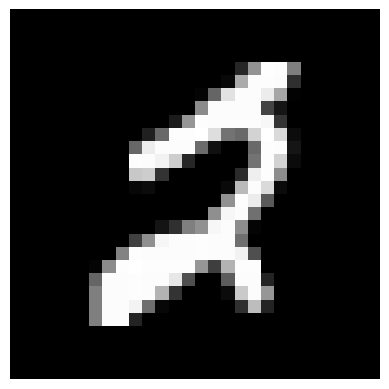

In [6]:
plt.imshow(images[0, 0], cmap="gray")
plt.axis("off")
plt.show()

Creating beta schedule and calculating alpha

In [7]:
T = 1000
beta_start = 1e-4
beta_end = 0.02
betas = torch.linspace(
    beta_start,
    beta_end,
    T,
    device=device
)
alphas = 1.0 - betas
alpha_time_t = torch.cumprod(alphas, dim=0)

Writing the "diffusion kernel", the calculation for how noisy the image should be at each timestep (starting with a linear schedule, so t will make the image noiser linearly)
Can change beta_start and beta_end to increase FID score if the forward pass introduces too much/too little noise at each step

In [8]:
def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    sqrt_alpha_time_t = torch.sqrt(alpha_time_t[t])
    sqrt_one_minus_alpha_time_t = torch.sqrt(1 - alpha_time_t[t])

    # Reshape so the values can be multiplied across the entire picture
    sqrt_alpha_time_t = sqrt_alpha_time_t[:, None, None, None]
    sqrt_one_minus_alpha_time_t = sqrt_one_minus_alpha_time_t[:, None, None, None]

    xt = (
        sqrt_alpha_time_t * x0
        + sqrt_one_minus_alpha_time_t * noise
    )

    return xt, noise

test forward passing using the scheduler

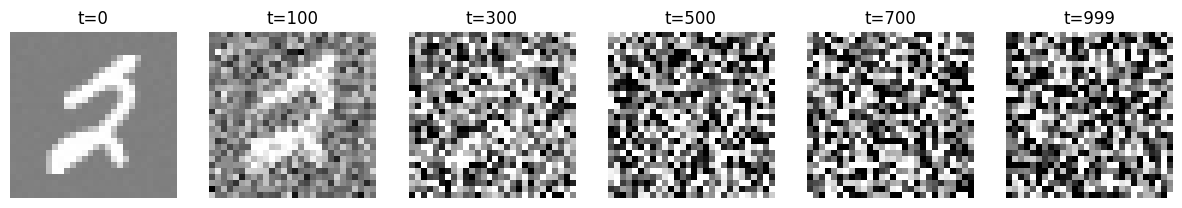

In [9]:
x0 = images[0:1].to(device)

timesteps = [0, 100, 300, 500, 700, 999]

fig, axes = plt.subplots(1, len(timesteps), figsize=(15, 3))

for ax, t_value in zip(axes, timesteps):
    t = torch.tensor([t_value], device=device)

    xt, _ = q_sample(x0, t)

    ax.imshow(
        xt[0, 0].to("cpu"),
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    ax.set_title(f"t={t_value}")
    ax.axis("off")

plt.show()

Developing the UNET to predict the noise given a noisy image and the timestamp

Step 1: encode the timestep t as a sinusoidal embedding to give the model more information/context about the differences in t and let it learn better

In [10]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        device = t.device

        half_dim = self.dim // 2

        emb_scale = math.log(10000) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(half_dim, device=device) * -emb_scale
        )

        emb = t.float()[:, None] * emb[None, :]

        emb = torch.cat(
            [torch.sin(emb), torch.cos(emb)],
            dim=1
        )

        return emb

we created the sin and cosine values using the scale (log(10000)/half_dim - 1), where the values end up being about evenly spaced out between 1 and 0 (1 -> 0.984 -> 0.972, etc)
then, put them all in a tensor, ran them through sine and cosine, then squashed them together using cat to get our final embedding, which is equivalent to a given t value, but with much more information so the machine can learn
The more dimensions are added to the embedding, the more the machine can see where t exactly falls since value 1 will change very quickly with t, value 2 will change slightly less quickly (since the logarithmic scale slightly decreases meaning the t value will have less effect on the final value)

In [11]:
time_emb = SinusoidalTimeEmbedding(64)

t = torch.tensor([0, 100, 500, 999], device=device)

print(time_emb(t).shape)

torch.Size([4, 64])


Now, creating the resblock, which is used to process the image and identify the diffusion timestep based on the image. The process is: normalize the data, use a nonlinear activation function, convolute the data, add the timestep embedding, then repeat the first 3 steps.

In [12]:
class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.norm1 = nn.GroupNorm(
            num_groups=8,
            num_channels=in_channels
        )

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.time_mlp = nn.Linear(
            time_dim,
            out_channels
        )

        self.norm2 = nn.GroupNorm(
            num_groups=8,
            num_channels=out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        if in_channels != out_channels:
            self.residual = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )
        else:
            self.residual = nn.Identity()

    def forward(self, x, t_emb):

        h = self.norm1(x)
        h = F.silu(h)
        h = self.conv1(h)

        # Add timestep information
        time_emb = self.time_mlp(t_emb)
        time_emb = time_emb[:, :, None, None]

        h = h + time_emb

        h = self.norm2(h)
        h = F.silu(h)
        h = self.conv2(h)

        return h + self.residual(x)

Now that the resblock has been built, we can build the model.
Architecture:
2 encoder blocks, 1 bottleneck, 2 decoder blocks
given the input and the time embedding, goes through the 2 down layers, the bottleneck, then the uplayers while concatenating to give one single output

In [13]:
class UNet(nn.Module):
    def __init__(
        self,
        in_channels=1,
        out_channels=1,
        base_channels=64,
        time_dim=128
    ):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        # Initial projection
        self.input_conv = nn.Conv2d(
            in_channels,
            base_channels,
            kernel_size=3,
            padding=1
        )

        # Encoder
        self.down1 = ResBlock(
            base_channels,
            base_channels,
            time_dim
        )

        self.downsample1 = nn.Conv2d(
            base_channels,
            base_channels * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.down2 = ResBlock(
            base_channels * 2,
            base_channels * 2,
            time_dim
        )

        self.downsample2 = nn.Conv2d(
            base_channels * 2,
            base_channels * 4,
            kernel_size=4,
            stride=2,
            padding=1
        )

        # Bottleneck
        self.mid1 = ResBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        self.mid2 = ResBlock(
            base_channels * 4,
            base_channels * 4,
            time_dim
        )

        # Decoder
        self.upsample1 = nn.ConvTranspose2d(
            base_channels * 4,
            base_channels * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up1 = ResBlock(
            base_channels * 4,
            base_channels * 2,
            time_dim
        )

        self.upsample2 = nn.ConvTranspose2d(
            base_channels * 2,
            base_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up2 = ResBlock(
            base_channels * 2,
            base_channels,
            time_dim
        )

        self.output = nn.Sequential(
            nn.GroupNorm(8, base_channels),
            nn.SiLU(),
            nn.Conv2d(
                base_channels,
                out_channels,
                kernel_size=3,
                padding=1
            )
        )

    def forward(self, x, t):

        t_emb = self.time_embedding(t)

        # Input
        x = self.input_conv(x)

        # Encoder
        d1 = self.down1(x, t_emb)

        x = self.downsample1(d1)

        d2 = self.down2(x, t_emb)

        x = self.downsample2(d2)

        # Bottleneck
        x = self.mid1(x, t_emb)
        x = self.mid2(x, t_emb)

        # Decoder
        x = self.upsample1(x)

        x = torch.cat([x, d2], dim=1)

        x = self.up1(x, t_emb)

        x = self.upsample2(x)

        x = torch.cat([x, d1], dim=1)

        x = self.up2(x, t_emb)

        return self.output(x)

In [14]:
model = UNet().to(device)
num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"{num_params:,} parameters")

4,789,057 parameters


In [15]:
x = torch.randn(
    8, 1, 28, 28, device=device
)

t = torch.randint(
    0, T,
    (8,), device=device
)

with torch.no_grad():
    output = model(x, t)

print(x.shape)
print(output.shape)

torch.Size([8, 1, 28, 28])
torch.Size([8, 1, 28, 28])


In [16]:
x0, labels = next(iter(train_loader))
x0, labels = x0.to(device), labels.to(device)


batch_size = x0.shape[0]

t = torch.randint(
    0,
    T,
    (batch_size,), device=device
)

xt, noise = q_sample(x0, t)

pred_noise = model(xt, t)

loss = F.mse_loss(
    pred_noise,
    noise
)

print(loss.item())

1.1061276197433472


training the model using predefined hyperparameters:

In [17]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)
num_epochs = 20

loss_history = []

for epoch in range(num_epochs):

    print("epoch number: ", epoch)

    model.train()

    for x0, _ in train_loader:
        x0 = x0.to(device)

        batch_size = x0.shape[0]

        # Random timestep for each image
        t = torch.randint(
            0,
            T,
            (batch_size,), device=device
        )

        # Random Gaussian noise
        noise = torch.randn_like(x0)

        # Forward diffusion
        xt, _ = q_sample(
            x0,
            t,
            noise
        )


        # Predict the noise
        pred_noise = model(
            xt,
            t
        )

        # DDPM loss
        loss = F.mse_loss(
            pred_noise,
            noise
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        loss_history.append(loss.item())

epoch number:  0
epoch number:  1
epoch number:  2
epoch number:  3
epoch number:  4
epoch number:  5
epoch number:  6
epoch number:  7
epoch number:  8
epoch number:  9
epoch number:  10
epoch number:  11
epoch number:  12
epoch number:  13
epoch number:  14
epoch number:  15
epoch number:  16
epoch number:  17
epoch number:  18
epoch number:  19


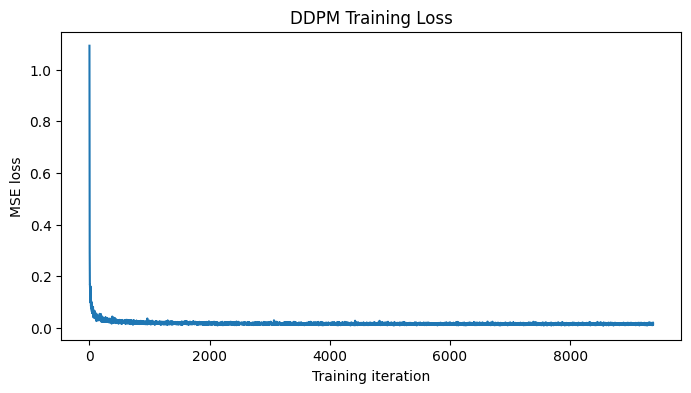

In [18]:
plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.xlabel("Training iteration")
plt.ylabel("MSE loss")
plt.title("DDPM Training Loss")

plt.show()

Create sampler, to use trained model to generate images

In [19]:
@torch.no_grad()
def sample_ddpm(
    model,
    n_samples,
    image_size=28
):
    model.eval()

    x = torch.randn(
        n_samples,
        1,
        image_size,
        image_size,
        device=device
    )

    for t_value in reversed(range(T)):

        t = torch.full(
            (n_samples,),
            t_value,
            device=device,
            dtype=torch.long
        )

        # Predict noise
        pred_noise = model(x, t)

        beta_t = betas[t_value]
        alpha_t = alphas[t_value]
        alpha_bar_t = alpha_time_t[t_value]

        # DDPM mean
        mean = (
            1 / torch.sqrt(alpha_t)
        ) * (
            x
            -
            (beta_t / torch.sqrt(1 - alpha_bar_t))
            * pred_noise
        )

        if t_value > 0:

            noise = torch.randn_like(x)

            variance = beta_t

            x = (
                mean
                + torch.sqrt(variance) * noise
            )

        else:
            x = mean

    return x

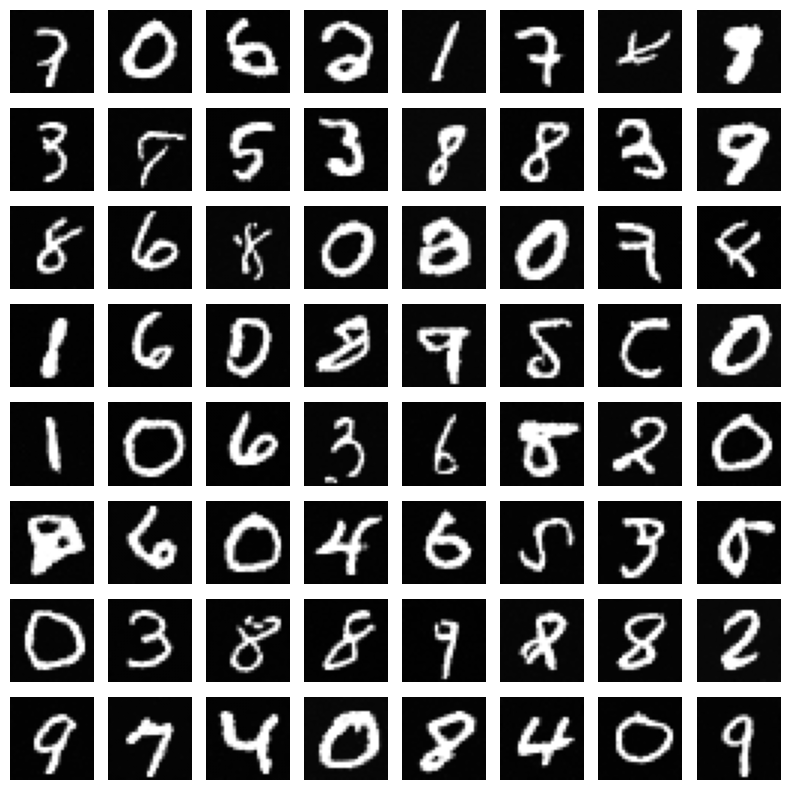

In [20]:
samples = sample_ddpm(
    model,
    n_samples=64
)
samples = (samples + 1) / 2
samples = samples.clamp(0, 1)
fig, axes = plt.subplots(
    8, 8,
    figsize=(8, 8)
)

for ax, image in zip(
    axes.flatten(),
    samples
):
    ax.imshow(
        image[0].cpu(),
        cmap="gray"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
import os
from PIL import Image

generated_dir = "./generated_mnist"
os.makedirs(generated_dir, exist_ok=True)

In [22]:
samples = sample_ddpm(model, n_samples=1000)

samples = (samples.clamp(-1, 1) + 1) / 2
samples = samples * 255
samples = samples.to(torch.uint8)

for i, img in enumerate(samples):
    img = img.squeeze(0).cpu().numpy()

    # Convert grayscale -> RGB
    img = np.stack([img, img, img], axis=-1)

    Image.fromarray(img).save(
        os.path.join(generated_dir, f"{i:05d}.png")
    )

In [23]:
img = Image.open("./generated_mnist/00000.png")

plt.imshow(img)
plt.axis("off")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: './generated_mnist/00000.png'

In [ ]:
fid_value = calculate_fid_given_paths(
    paths=['./data', './generated_mnist'],
    batch_size=50,
    device='cuda',
    dims=2048
)
print(f"FID score: {fid_value}")